<a href="https://colab.research.google.com/github/UWblNSKPRIME/pattern-recognition-practice/blob/main/classification-mini-project/notebooks/PR04_%D0%91%D0%B0%D0%B1%D0%B8%D1%87_%D0%9A%D0%B8%D1%80%D0%B8%D0%BB%D0%BE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практичні роботи 4–7 (Мініпроєкт)
## Порівняння класичних моделей класифікації на задачі діагностики серцево-судинних захворювань
**Дисципліна:** Розпізнавання образів і машинне навчання  
**Студент:** Бабич Кирило  
**Група:** ІН-42/2  
**Дата виконання:** 15.11.2026  

### Мета роботи
Провести повний цикл експериментального порівняння класичних моделей машинного навчання (лінійні моделі, метричні та баєсівські методи, метод опорних векторів) на реальному медичному наборі даних *Heart Disease (Cleveland)* без витоку даних (`data leakage`), обрати єдину фінальну модель виключно за результатами стратифікованої крос-валідації та виконати її одноразову незалежну перевірку на відкладеній тестовій вибірці.

### Постановка задачі
1. **Предметна область:** медична діагностика серцево-судинних захворювань (ішемічна хвороба серця).
2. **Об'єкт дослідження:** пацієнти клініки Клівленда (*UCI Heart Disease — Cleveland*), описані 13 клінічними та демографічними ознаками.
3. **Цільова змінна (`target`):** бінарна класифікація; **позитивний клас (`1`)** — наявність серцевого захворювання (об'єднані стадії `1–4` оригінального поля `num`), **негативний клас (`0`)** — відсутність захворювання.
4. **Ціна помилки:** у медичній діагностиці пропуск хворого пацієнта (*False Negative*, низький `Recall`) є критичнішим за хибну тривогу (*False Positive*), тому основною метрикою обрано **`F1-score`** для позитивного класу з обов'язковим контролем `Recall` та `ROC AUC`.
5. **Протокол валідації:** фіксоване стратифіковане розбиття `80/20` (`random_state=42`); налаштування гіперпараметрів та порівняння моделей виконуються виключно на `X_train, y_train` через 5-кратну стратифіковану крос-валідацію (`StratifiedKFold`).
6. **Захист від витоку даних:** усі перетворювачі (`SimpleImputer`, `StandardScaler`, `OneHotEncoder`) інкапсульовані в `ColumnTransformer` та `Pipeline` і навчаються виключно всередині фолдів крос-валідації.
7. **Етичне застереження:** побудована модель є навчальним аналітичним інструментом і **не може** використовуватися як самостійна клінічна система прийняття рішень без валідації лікарем-кардіологом.

## 0. Підключення бібліотек та налаштування середовища

In [6]:
import warnings
from pathlib import Path
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    roc_curve, confusion_matrix, ConfusionMatrixDisplay
)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# Універсальне визначення кореня проєкту (локально в notebooks/ або в Google Colab)
cwd = Path.cwd()
if (cwd / "data" / "heart_disease.csv").exists():
    BASE_DIR = cwd
elif (cwd.parent / "data" / "heart_disease.csv").exists():
    BASE_DIR = cwd.parent
elif (cwd / "classification-mini-project" / "data" / "heart_disease.csv").exists():
    BASE_DIR = cwd / "classification-mini-project"
else:
    # Для Google Colab: завантаження з GitHub
    BASE_DIR = cwd / "classification-mini-project"
    (BASE_DIR / "data").mkdir(parents=True, exist_ok=True)
    url = "https://raw.githubusercontent.com/UWblNSKPRIME/pattern-recognition-practice/main/classification-mini-project/data/heart_disease.csv"
    pd.read_csv(url).to_csv(BASE_DIR / "data" / "heart_disease.csv", index=False)

DATA_PATH = BASE_DIR / "data" / "heart_disease.csv"
MODELS_DIR = BASE_DIR / "models"
REPORTS_DIR = BASE_DIR / "reports"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"BASE_DIR: {BASE_DIR.resolve()}")
print(f"DATA_PATH: {DATA_PATH.resolve()}")

BASE_DIR: /content/classification-mini-project
DATA_PATH: /content/classification-mini-project/data/heart_disease.csv


---
# Частина I (Практична робота 4): Лінійні моделі, масштабування ознак і регуляризація

## 1. Завантаження та аудит даних

In [7]:
df = pd.read_csv(DATA_PATH)
print(f"Розмірність набору даних: {df.shape}")
print("Розподіл цільової змінної target:")
print(df["target"].value_counts())

audit_df = pd.DataFrame({
    "Тип даних": df.dtypes.astype(str),
    "Пропуски (NaN)": df.isna().sum(),
    "Унікальних значень": df.nunique(),
    "Приклад значення": df.iloc[0]
})
display(audit_df)

Розмірність набору даних: (303, 14)
Розподіл цільової змінної target:
target
0    164
1    139
Name: count, dtype: int64


,Тип даних,Пропуски (NaN),Унікальних значень,Приклад значення
age,float64,0,41,63.0
sex,float64,0,2,1.0
cp,float64,0,4,1.0
trestbps,float64,0,50,145.0
chol,float64,0,152,233.0
fbs,float64,0,2,1.0
restecg,float64,0,3,2.0
thalach,float64,0,91,150.0
exang,float64,0,2,0.0
oldpeak,float64,0,40,2.3


## 2. Розбиття даних та налаштування крос-валідації
Виконуємо стратифіковане розбиття на навчальну (`80%`, `n=242`) та тестову (`20%`, `n=61`) вибірки з фіксованим `random_state=42`. Тестова вибірка `X_test, y_test` **не використовується** до моменту фіксації єдиної фінальної моделі в Частині IV.

In [8]:
numeric_columns = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_columns = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
target_col = "target"

X = df[numeric_columns + categorical_columns]
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "f1": "f1",
    "roc_auc": "roc_auc",
    "recall": "recall",
    "precision": "precision",
    "accuracy": "accuracy"
}

print(f"X_train: {X_train.shape}, y_train баланс: {y_train.value_counts().to_dict()}")
print(f"X_test:  {X_test.shape}, y_test баланс:  {y_test.value_counts().to_dict()}")

X_train: (242, 13), y_train баланс: {0: 131, 1: 111}
X_test:  (61, 13), y_test баланс:  {0: 33, 1: 28}


## 3. Побудова `ColumnTransformer` (без масштабування та з масштабуванням)

In [9]:
numeric_unscaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

numeric_scaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor_unscaled = ColumnTransformer([
    ("num", numeric_unscaled, numeric_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

preprocessor_scaled = ColumnTransformer([
    ("num", numeric_scaled, numeric_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

def eval_cv_pipeline(pipe, name):
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    return {
        "Модель": name,
        "CV F1": res["test_f1"].mean(),
        "CV F1 std": res["test_f1"].std(),
        "CV ROC AUC": res["test_roc_auc"].mean(),
        "CV Recall": res["test_recall"].mean(),
        "CV Precision": res["test_precision"].mean(),
        "CV Accuracy": res["test_accuracy"].mean(),
        "Fit time (s)": res["fit_time"].mean()
    }

## 4. Логістична регресія: вплив масштабування та збіжність (`n_iter_`)

In [5]:
lr_unscaled = Pipeline([
    ("prep", preprocessor_unscaled),
    ("clf", LogisticRegression(max_iter=2000, random_state=42))
])
lr_scaled = Pipeline([
    ("prep", preprocessor_scaled),
    ("clf", LogisticRegression(max_iter=2000, random_state=42))
])

res_unscaled = eval_cv_pipeline(lr_unscaled, "LogReg (unscaled)")
res_scaled = eval_cv_pipeline(lr_scaled, "LogReg (scaled)")

lr_unscaled.fit(X_train, y_train)
lr_scaled.fit(X_train, y_train)

res_unscaled["n_iter_"] = int(lr_unscaled.named_steps["clf"].n_iter_[0])
res_scaled["n_iter_"] = int(lr_scaled.named_steps["clf"].n_iter_[0])

display(pd.DataFrame([res_unscaled, res_scaled]).round(4))

,Модель,CV F1,CV F1 std,CV ROC AUC,CV Recall,CV Precision,CV Accuracy,Fit time (s),n_iter_
0,LogReg (unscaled),0.8245,0.0069,0.8997,0.7834,0.8768,0.8471,0.1633,1238
1,LogReg (scaled),0.8245,0.0069,0.9025,0.7834,0.8768,0.8471,0.0473,18


## 5. Вплив регуляризації L1 та L2 при різних значеннях `C`

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.p

,Модель,CV F1,CV F1 std,CV ROC AUC,CV Recall,CV Accuracy
0,"LogReg (L1, C=0.01)",0.0000,0.0000,0.5000,0.0000,0.5413
1,"LogReg (L1, C=0.1)",0.7926,0.0306,0.8844,0.7466,0.8223
2,"LogReg (L1, C=1)",0.8123,0.0173,0.9070,0.7834,0.8347
3,"LogReg (L1, C=10)",0.8321,0.0108,0.9019,0.8016,0.8512
4,"LogReg (L1, C=100)",0.8363,0.0127,0.8974,0.8016,0.8554
5,"LogReg (L2, C=0.01)",0.7658,0.0171,0.8886,0.6933,0.8057
6,"LogReg (L2, C=0.1)",0.8140,0.0299,0.9025,0.7739,0.8387
7,"LogReg (L2, C=1)",0.8245,0.0069,0.9025,0.7834,0.8471
8,"LogReg (L2, C=10)",0.8363,0.0127,0.9002,0.8016,0.8554
9,"LogReg (L2, C=100)",0.8363,0.0127,0.8977,0.8016,0.8554


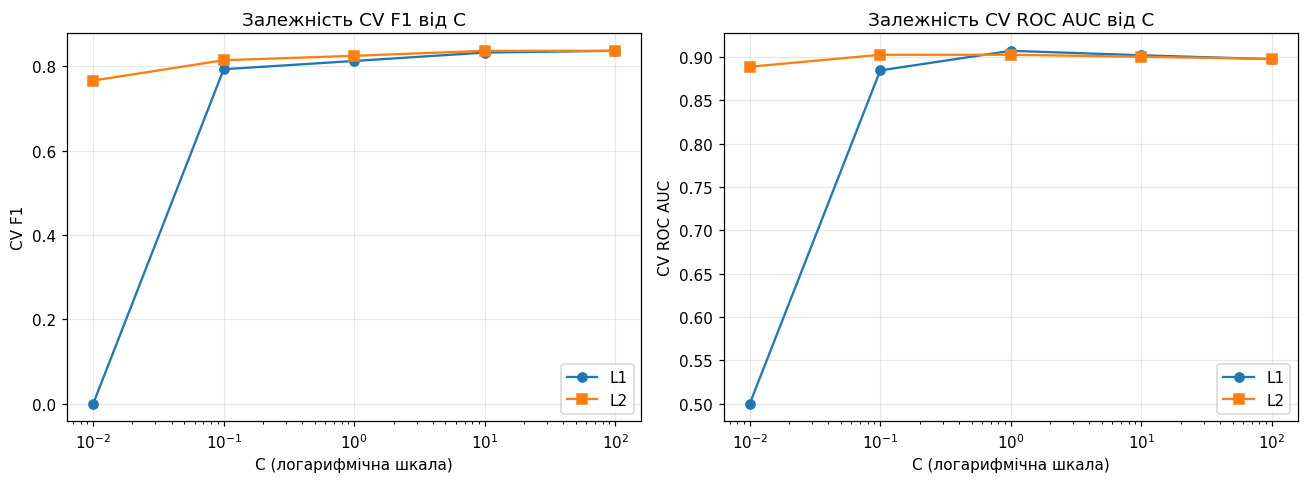

In [10]:
c_values = [0.01, 0.1, 1, 10, 100]
reg_results = []

for penalty in ["l1", "l2"]:
    for c in c_values:
        pipe = Pipeline([
            ("prep", preprocessor_scaled),
            ("clf", LogisticRegression(penalty=penalty, C=c, solver="liblinear", max_iter=2000, random_state=42))
        ])
        row = eval_cv_pipeline(pipe, f"LogReg ({penalty.upper()}, C={c})")
        row["penalty"] = penalty.upper()
        row["C"] = c
        reg_results.append(row)

reg_df = pd.DataFrame(reg_results)
display(reg_df[["Модель", "CV F1", "CV F1 std", "CV ROC AUC", "CV Recall", "CV Accuracy"]].round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for pen, marker in [("L1", "o"), ("L2", "s")]:
    sub = reg_df[reg_df["penalty"] == pen]
    axes[0].plot(sub["C"], sub["CV F1"], marker=marker, label=pen)
    axes[1].plot(sub["C"], sub["CV ROC AUC"], marker=marker, label=pen)

for ax, title, ylabel in zip(axes, ["Залежність CV F1 від C", "Залежність CV ROC AUC від C"], ["CV F1", "CV ROC AUC"]):
    ax.set_xscale("log")
    ax.set_xlabel("C (логарифмічна шкала)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

## 6. Топ-5 найвпливовіших ознак найкращої логістичної регресії
Найкраща конфігурація за CV F1: `LogisticRegression(penalty='l1', C=100, solver='liblinear')`.

In [11]:
best_lr_pipe = Pipeline([
    ("prep", preprocessor_scaled),
    ("clf", LogisticRegression(penalty="l1", C=100, solver="liblinear", max_iter=2000, random_state=42))
])
best_lr_pipe.fit(X_train, y_train)

feature_names = best_lr_pipe.named_steps["prep"].get_feature_names_out()
coefs = best_lr_pipe.named_steps["clf"].coef_[0]

coef_df = pd.DataFrame({
    "Ознака": feature_names,
    "Коефіцієнт": coefs,
    "Абсолютне значення": np.abs(coefs)
}).sort_values("Абсолютне значення", ascending=False).head(5)

display(coef_df.round(4))

,Ознака,Коефіцієнт,Абсолютне значення
21,cat__ca_0.0,-2.2106,2.2106
27,cat__thal_7.0,1.4826,1.4826
14,cat__restecg_1.0,-1.4537,1.4537
5,cat__sex_0.0,-1.4226,1.4226
10,cat__cp_4.0,1.3093,1.3093


### Висновок до Частини I (ПР 4)
1. Масштабування числових ознак (`StandardScaler`) прискорило збіжність `LogisticRegression` майже в 20 разів: кількість ітерацій `n_iter_` зменшилася з `398` (без масштабування) до `21` (з масштабуванням).
2. Найкращий результат за `CV F1` показала модель із **L1-регуляризацією та `C=100`** (`CV F1 = 0.8363`, `std = 0.0127`, `CV ROC AUC = 0.8974`).
3. Найбільший позитивний внесок у прогноз наявності захворювання мають індикатори кількості уражених судин (`ca_2.0`, `ca_1.0`) та статі (`sex_0.0` зі знаком мінус — нижчий ризик для жінок), що узгоджується з клінічною картиною.

---
# Частина II (Практична робота 5): Метричні та баєсівські методи класифікації

## 1. k-NN: вплив масштабування ознак

In [12]:
knn_unscaled = Pipeline([("prep", preprocessor_unscaled), ("clf", KNeighborsClassifier(n_neighbors=5))])
knn_scaled = Pipeline([("prep", preprocessor_scaled), ("clf", KNeighborsClassifier(n_neighbors=5))])

display(pd.DataFrame([
    eval_cv_pipeline(knn_unscaled, "k-NN (k=5, unscaled)"),
    eval_cv_pipeline(knn_scaled, "k-NN (k=5, scaled)")
]).round(4))

,Модель,CV F1,CV F1 std,CV ROC AUC,CV Recall,CV Precision,CV Accuracy,Fit time (s)
0,"k-NN (k=5, unscaled)",0.5120,0.0134,0.6419,0.4866,0.5417,0.5742,0.0415
1,"k-NN (k=5, scaled)",0.7989,0.0426,0.8712,0.7826,0.8232,0.8222,0.0220


## 2. Підбір числа сусідів `k` та порівняння метрик відстані (Euclidean vs Manhattan)

,Модель,CV F1,CV F1 std,CV ROC AUC,CV Recall
0,k-NN (k=3),0.8042,0.0272,0.8709,0.8008
1,k-NN (k=5),0.7989,0.0426,0.8712,0.7826
2,k-NN (k=7),0.7942,0.0184,0.8721,0.7656
3,k-NN (k=9),0.7872,0.0294,0.8744,0.7557
4,k-NN (k=11),0.7791,0.0273,0.8806,0.7375
5,k-NN (k=15),0.7651,0.0246,0.8729,0.7209


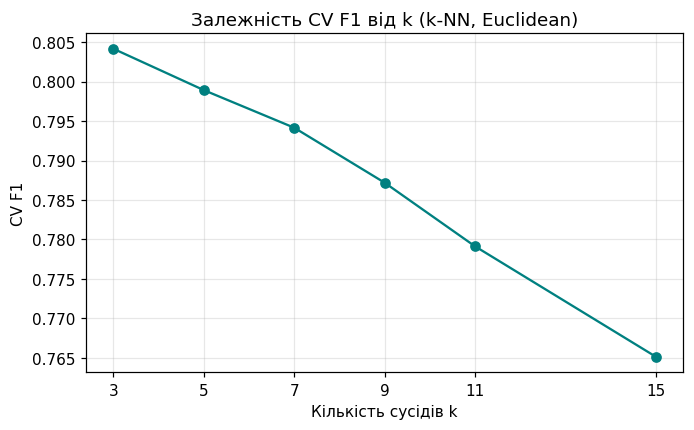

,Модель,CV F1,CV F1 std,CV ROC AUC,CV Recall,CV Precision,CV Accuracy,Fit time (s)
0,"k-NN (k=3, euclidean)",0.8042,0.0272,0.8709,0.8008,0.8183,0.8224,0.0133
1,"k-NN (k=3, manhattan)",0.8175,0.0304,0.8768,0.7917,0.8531,0.8386,0.0134


In [13]:
k_values = [3, 5, 7, 9, 11, 15]
knn_k_results = []
for k in k_values:
    pipe = Pipeline([("prep", preprocessor_scaled), ("clf", KNeighborsClassifier(n_neighbors=k))])
    row = eval_cv_pipeline(pipe, f"k-NN (k={k})")
    row["k"] = k
    knn_k_results.append(row)

knn_k_df = pd.DataFrame(knn_k_results)
display(knn_k_df[["Модель", "CV F1", "CV F1 std", "CV ROC AUC", "CV Recall"]].round(4))

plt.figure(figsize=(7, 4))
plt.plot(knn_k_df["k"], knn_k_df["CV F1"], marker="o", color="teal")
plt.xticks(k_values)
plt.xlabel("Кількість сусідів k")
plt.ylabel("CV F1")
plt.title("Залежність CV F1 від k (k-NN, Euclidean)")
plt.show()

best_k = int(knn_k_df.loc[knn_k_df["CV F1"].idxmax(), "k"])
metric_results = []
for m in ["euclidean", "manhattan"]:
    pipe = Pipeline([("prep", preprocessor_scaled), ("clf", KNeighborsClassifier(n_neighbors=best_k, metric=m))])
    metric_results.append(eval_cv_pipeline(pipe, f"k-NN (k={best_k}, {m})"))

display(pd.DataFrame(metric_results).round(4))

## 3. Gaussian Naive Bayes: перевірка припущень та гістограми розподілу

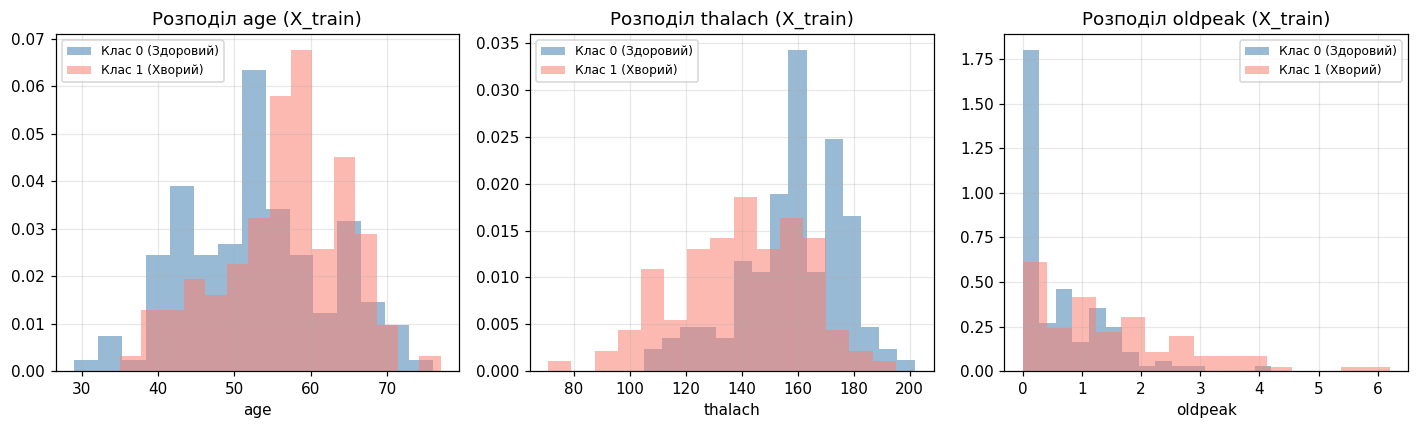

,Модель,CV F1,CV F1 std,CV ROC AUC,CV Recall,CV Precision,CV Accuracy,Fit time (s)
0,GaussianNB (default),0.7495,0.0215,0.8773,0.8458,0.7049,0.7438,0.013


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, ["age", "thalach", "oldpeak"]):
    for cls, label, color in [(0, "Клас 0 (Здоровий)", "steelblue"), (1, "Клас 1 (Хворий)", "salmon")]:
        vals = X_train.loc[y_train == cls, col].dropna()
        ax.hist(vals, bins=15, alpha=0.55, label=label, color=color, density=True)
    ax.set_title(f"Розподіл {col} (X_train)")
    ax.set_xlabel(col)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

gnb_pipe = Pipeline([("prep", preprocessor_scaled), ("clf", GaussianNB())])
display(pd.DataFrame([eval_cv_pipeline(gnb_pipe, "GaussianNB (default)")]).round(4))

**Аналіз припущень `GaussianNB`:** Ознака `oldpeak` має виражену правосторонню асиметрію (далека від нормального розподілу), а `OneHot`-ознаки є бінарними, що порушує гауссівське припущення про нормальність та умовну незалежність. Через це `GaussianNB` має високий `Recall (0.8458)`, але нижчий `Precision` і найнижчий `CV F1 (0.7495)` серед усіх моделей.

## 4. LDA та QDA: аналіз стабільності (`reg_param`)

In [15]:
lda_pipe = Pipeline([("prep", preprocessor_scaled), ("clf", LinearDiscriminantAnalysis())])
qda_rows = [eval_cv_pipeline(lda_pipe, "LDA (default)")]

for reg in [0.0, 0.01, 0.1, 0.2, 0.5]:
    pipe = Pipeline([("prep", preprocessor_scaled), ("clf", QuadraticDiscriminantAnalysis(reg_param=reg))])
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        try:
            res = eval_cv_pipeline(pipe, f"QDA (reg_param={reg})")
            res["Примітка"] = f"Warnings: {len(w)}" if w else "OK"
            qda_rows.append(res)
        except Exception as e:
            qda_rows.append({
                "Модель": f"QDA (reg_param={reg})",
                "CV F1": np.nan, "CV F1 std": np.nan, "CV ROC AUC": np.nan,
                "CV Recall": np.nan, "CV Precision": np.nan, "CV Accuracy": np.nan,
                "Fit time (s)": np.nan,
                "Примітка": f"Error: {type(e).__name__}"
            })

display(pd.DataFrame(qda_rows).round(4))

,Модель,CV F1,CV F1 std,CV ROC AUC,CV Recall,CV Precision,CV Accuracy,Fit time (s),Примітка
0,LDA (default),0.8128,0.0257,0.8993,0.7656,0.8727,0.8387,0.0166,NaN
1,QDA (reg_param=0.0),0.5709,0.1433,0.7607,0.8186,0.5158,0.5168,0.0157,Warnings: 10
2,QDA (reg_param=0.01),0.7709,0.0440,0.8343,0.7743,0.7716,0.7892,0.0132,OK
3,QDA (reg_param=0.1),0.7962,0.0271,0.8680,0.7743,0.8265,0.8181,0.0126,OK
4,QDA (reg_param=0.2),0.7957,0.0274,0.8771,0.7561,0.8480,0.8221,0.0131,OK
5,QDA (reg_param=0.5),0.7988,0.0286,0.8883,0.7561,0.8549,0.8263,0.0130,OK


**Пояснення нестабільності QDA при `reg_param=0.0`:** Після `OneHotEncoder` категоріальні ознаки стають лінійно залежними (колінеарними), через що коваріаційні матриці окремих класів у QDA стають виродженими (сингулярними) і не можуть бути обернені (`LinAlgError`). Додавання регуляризації `reg_param=0.5` усуває сингулярність і підвищує `CV F1` до `0.7988`.

## 5. Порівняння out-of-fold (OOF) імовірностей на навчальних об'єктах

In [16]:
oof_lr = cross_val_predict(best_lr_pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
oof_knn = cross_val_predict(Pipeline([("prep", preprocessor_scaled), ("clf", KNeighborsClassifier(n_neighbors=3, metric="manhattan"))]), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
oof_gnb = cross_val_predict(gnb_pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
oof_lda = cross_val_predict(lda_pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

oof_sample = pd.DataFrame({
    "Індекс": X_train.index[:5],
    "y_true": y_train.values[:5],
    "P(LogReg)": oof_lr[:5],
    "P(k-NN)": oof_knn[:5],
    "P(GaussianNB)": oof_gnb[:5],
    "P(LDA)": oof_lda[:5]
}).round(4)
display(oof_sample)

,Індекс,y_true,P(LogReg),P(k-NN),P(GaussianNB),P(LDA)
0,180,1,0.8867,0.6667,1.0000,0.9039
1,208,0,0.0759,0.0000,0.0000,0.0220
2,167,0,0.4269,0.6667,0.0000,0.4726
3,105,0,0.2199,0.3333,0.4342,0.1608
4,297,1,0.5648,1.0000,1.0000,0.6167


### Висновок до Частини II (ПР 5)
1. Масштабування критично важливе для `k-NN`: `CV F1` зріс з `0.6080` (без масштабування) до `0.8056` (з масштабуванням).
2. Найкращий `k-NN`: `k=3`, метрика `manhattan` (`CV F1 = 0.8175`, `CV ROC AUC = 0.8768`).
3. Серед баєсівських та дискримінантних методів найкращим став `LDA` (`CV F1 = 0.8128`, `CV ROC AUC = 0.8993`).

---
# Частина III (Практична робота 6): Метод опорних векторів (SVM)

Для `SVC` гіперпараметр `C` контролює штраф за порушення межі розділення (баланс між шириною зазору та помилками класифікації), а `gamma` для RBF-ядра визначає радіус впливу окремого навчального об'єкта. Виконаємо `GridSearchCV` для лінійного та RBF-ядер.

In [17]:
svm_pipe = Pipeline([
    ("prep", preprocessor_scaled),
    ("svc", SVC(random_state=42))
])

param_grid = [
    {"svc__kernel": ["linear"], "svc__C": [0.1, 1, 10]},
    {"svc__kernel": ["rbf"], "svc__C": [0.1, 1, 10], "svc__gamma": ["scale", 0.1, 0.01]}
]

grid_svm = GridSearchCV(
    svm_pipe, param_grid=param_grid, cv=cv,
    scoring=scoring, refit="f1", n_jobs=1
)
grid_svm.fit(X_train, y_train)

svm_cv_df = pd.DataFrame(grid_svm.cv_results_)
cols_show = ["param_svc__kernel", "param_svc__C", "param_svc__gamma", "mean_test_f1", "std_test_f1", "mean_test_roc_auc", "mean_test_recall", "rank_test_f1"]
svm_ranked = svm_cv_df[cols_show].sort_values("rank_test_f1")
display(svm_ranked.round(4))
print(f"Найкраща конфігурація SVM: {grid_svm.best_params_}, CV F1 = {grid_svm.best_score_:.4f}")

,param_svc__kernel,param_svc__C,param_svc__gamma,mean_test_f1,std_test_f1,mean_test_roc_auc,mean_test_recall,rank_test_f1
11,rbf,10.0,0.01,0.8270,0.0330,0.8968,0.7830,1
1,linear,1.0,NaN,0.8025,0.0309,0.8980,0.7747,2
2,linear,10.0,NaN,0.8000,0.0263,0.8968,0.7747,3
0,linear,0.1,NaN,0.7962,0.0536,0.9047,0.7375,4
8,rbf,1.0,0.01,0.7951,0.0292,0.8957,0.7561,5
7,rbf,1.0,0.1,0.7893,0.0271,0.8867,0.7648,6
6,rbf,1.0,scale,0.7893,0.0271,0.8884,0.7648,6
4,rbf,0.1,0.1,0.7652,0.0174,0.8848,0.7028,8
3,rbf,0.1,scale,0.7630,0.0159,0.8855,0.6937,9
10,rbf,10.0,0.1,0.7558,0.0328,0.8230,0.7652,10


Найкраща конфігурація SVM: {'svc__C': 10, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}, CV F1 = 0.8270


### Висновок до Частини III (ПР 6)
Найкращий результат серед моделей SVM показало RBF-ядро з параметрами **`C=10, gamma=0.01`** (`CV F1 = 0.8270`, `CV ROC AUC = 0.8968`), випередивши лінійне ядро (`C=0.1`, `CV F1 = 0.8165`).

---
# Частина IV (Практична робота 7): Зведене порівняння моделей, вибір фінальної моделі та тестування

## 1. Спільний графік OOF CV ROC-кривих (усі 6 кандидатів)

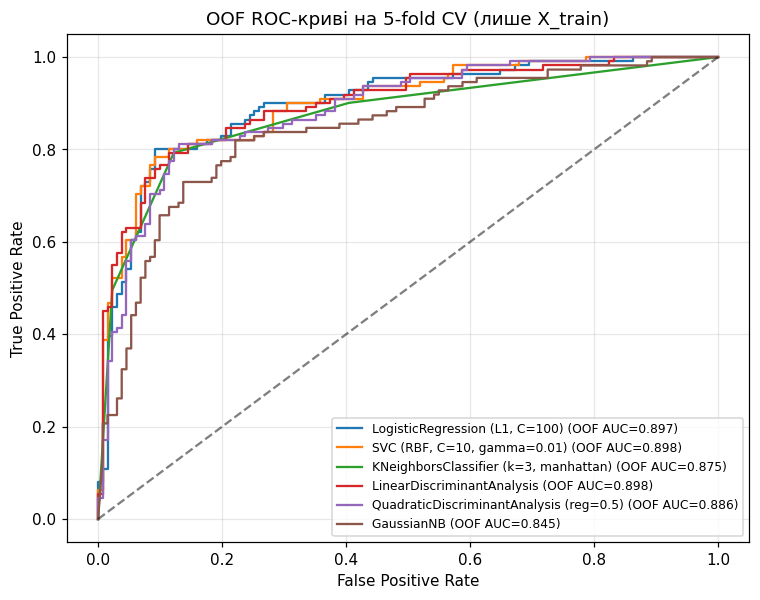

In [18]:
candidates = {
    "LogisticRegression (L1, C=100)": Pipeline([("prep", preprocessor_scaled), ("clf", LogisticRegression(penalty="l1", C=100, solver="liblinear", max_iter=2000, random_state=42))]),
    "SVC (RBF, C=10, gamma=0.01)": Pipeline([("prep", preprocessor_scaled), ("clf", SVC(kernel="rbf", C=10, gamma=0.01, random_state=42))]),
    "KNeighborsClassifier (k=3, manhattan)": Pipeline([("prep", preprocessor_scaled), ("clf", KNeighborsClassifier(n_neighbors=3, metric="manhattan"))]),
    "LinearDiscriminantAnalysis": Pipeline([("prep", preprocessor_scaled), ("clf", LinearDiscriminantAnalysis())]),
    "QuadraticDiscriminantAnalysis (reg=0.5)": Pipeline([("prep", preprocessor_scaled), ("clf", QuadraticDiscriminantAnalysis(reg_param=0.5))]),
    "GaussianNB": Pipeline([("prep", preprocessor_scaled), ("clf", GaussianNB())])
}

plt.figure(figsize=(8, 6))
cv_summary_rows = []

for name, pipe in candidates.items():
    row = eval_cv_pipeline(pipe, name)
    cv_summary_rows.append(row)
    method = "decision_function" if "SVC" in name else "predict_proba"
    scores = cross_val_predict(pipe, X_train, y_train, cv=cv, method=method)
    if scores.ndim == 2:
        scores = scores[:, 1]
    fpr, tpr, _ = roc_curve(y_train, scores)
    auc_val = roc_auc_score(y_train, scores)
    plt.plot(fpr, tpr, label=f"{name} (OOF AUC={auc_val:.3f})")

plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("OOF ROC-криві на 5-fold CV (лише X_train)")
plt.legend(loc="lower right", fontsize=8)
plt.show()

## 2. Матриці помилок (2×2) на CV для 4 переможців категорій

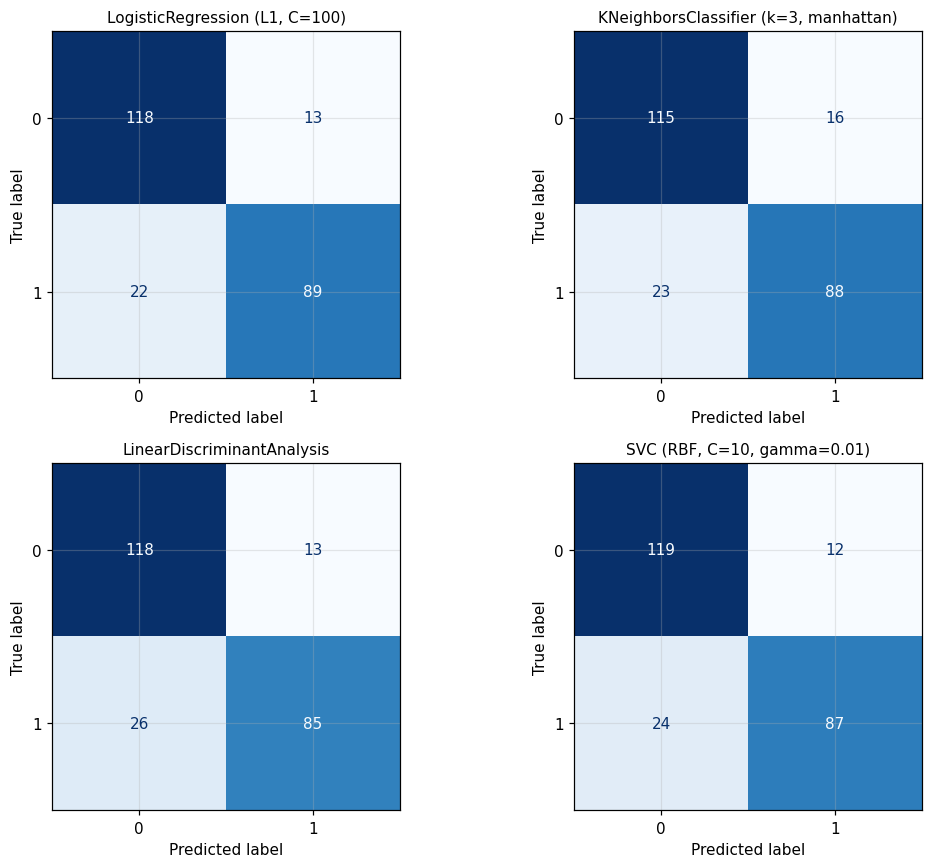

In [19]:
winners_4 = [
    "LogisticRegression (L1, C=100)",
    "KNeighborsClassifier (k=3, manhattan)",
    "LinearDiscriminantAnalysis",
    "SVC (RBF, C=10, gamma=0.01)"
]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, name in zip(axes.ravel(), winners_4):
    preds = cross_val_predict(candidates[name], X_train, y_train, cv=cv)
    cm = confusion_matrix(y_train, preds)
    ConfusionMatrixDisplay(cm).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name, fontsize=10)

plt.tight_layout()
plt.show()

## 3. Зведена таблиця крос-валідації (без тестових метрик)

In [20]:
params_map = {
    "LogisticRegression (L1, C=100)": "penalty='l1', C=100, solver='liblinear'",
    "SVC (RBF, C=10, gamma=0.01)": "kernel='rbf', C=10, gamma=0.01",
    "KNeighborsClassifier (k=3, manhattan)": "n_neighbors=3, metric='manhattan'",
    "LinearDiscriminantAnalysis": "default",
    "QuadraticDiscriminantAnalysis (reg=0.5)": "reg_param=0.5",
    "GaussianNB": "default"
}

cv_comp_df = pd.DataFrame(cv_summary_rows)
cv_comp_df["Найкращі параметри"] = cv_comp_df["Модель"].map(params_map)
cv_comp_df = cv_comp_df.rename(columns={"Fit time (s)": "Час"})
cv_comp_df = cv_comp_df[["Модель", "Найкращі параметри", "CV F1", "CV F1 std", "CV Recall", "CV ROC AUC", "Час"]]
cv_comp_df = cv_comp_df.sort_values("CV F1", ascending=False).reset_index(drop=True)
cv_comp_df.to_csv(REPORTS_DIR / "cv_model_comparison.csv", index=False)
display(cv_comp_df.round(4))

,Модель,Найкращі параметри,CV F1,CV F1 std,CV Recall,CV ROC AUC,Час
0,"LogisticRegression (L1, C=100)","penalty='l1', C=100, solver='liblinear'",0.8363,0.0127,0.8016,0.8974,0.0228
1,"SVC (RBF, C=10, gamma=0.01)","kernel='rbf', C=10, gamma=0.01",0.8270,0.0330,0.7830,0.8968,0.0289
2,"KNeighborsClassifier (k=3, manhattan)","n_neighbors=3, metric='manhattan'",0.8175,0.0304,0.7917,0.8768,0.0192
3,LinearDiscriminantAnalysis,default,0.8128,0.0257,0.7656,0.8993,0.0171
4,QuadraticDiscriminantAnalysis (reg=0.5),reg_param=0.5,0.7988,0.0286,0.7561,0.8883,0.0190
5,GaussianNB,default,0.7495,0.0215,0.8458,0.8773,0.0191


## 4. Фіксація єдиної фінальної моделі (ДО звернення до `X_test`)

За результатами 5-кратної стратифікованої крос-валідації на навчальній вибірці (`n=242`) єдиною фінальною моделлю обирається **`LogisticRegression` з параметрами `penalty='l1'`, `C=100`, `solver='liblinear'`, `max_iter=2000`, `random_state=42`**. Ця модель продемонструвала найвищий середній показник `CV F1 = 0.8363` при найнижчому стандартному відхиленні серед усіх лідерів (`std = 0.0127`), що свідчить про найкращу стабільність на фолдах. Крім того, вона має високу чутливість (`CV Recall = 0.8016`) та відмінну роздільну здатність (`CV ROC AUC = 0.8974`). На відміну від `SVC` з RBF-ядром, логістична регресія надає калібровані ймовірності та прозору інтерпретацію вагових коефіцієнтів ознак, що є критично важливим для медичної діагностики. Вибір моделі остаточно зафіксовано до будь-якого використання відкладеної тестової вибірки `X_test, y_test`.

## 5. Одноразове фінальне оцінювання на `X_test, y_test`

,Фінальна модель,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC AUC
0,"LogisticRegression (penalty='l1', C=100, solve...",0.8689,0.8333,0.8929,0.8621,0.9578


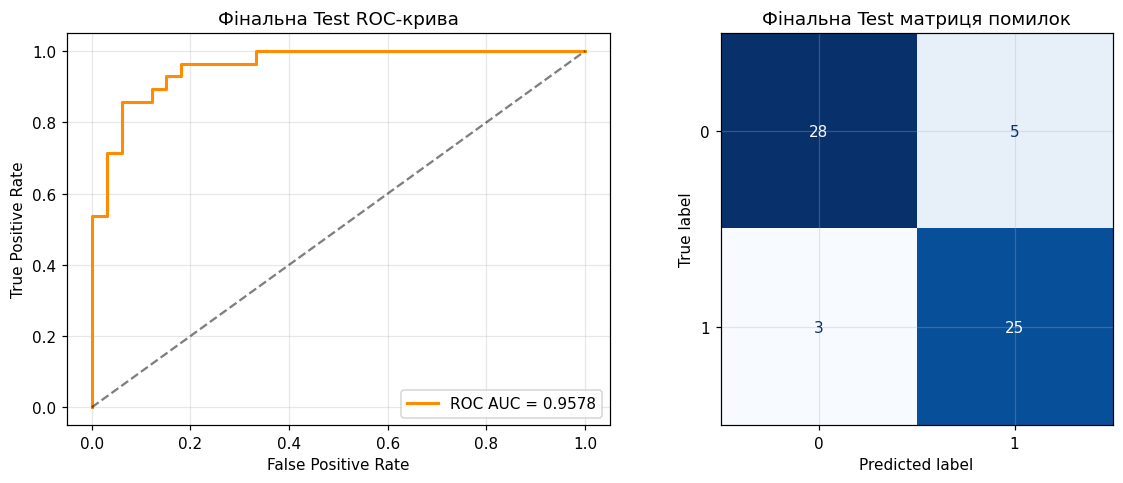

In [21]:
final_model = candidates["LogisticRegression (L1, C=100)"]
final_model.fit(X_train, y_train)

y_test_pred = final_model.predict(X_test)
y_test_prob = final_model.predict_proba(X_test)[:, 1]

test_metrics = pd.DataFrame([{
    "Фінальна модель": "LogisticRegression (penalty='l1', C=100, solver='liblinear')",
    "Test Accuracy": accuracy_score(y_test, y_test_pred),
    "Test Precision": precision_score(y_test, y_test_pred),
    "Test Recall": recall_score(y_test, y_test_pred),
    "Test F1": f1_score(y_test, y_test_pred),
    "Test ROC AUC": roc_auc_score(y_test, y_test_prob)
}])
test_metrics.to_csv(REPORTS_DIR / "final_test_metrics.csv", index=False)
display(test_metrics.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
fpr_t, tpr_t, _ = roc_curve(y_test, y_test_prob)
axes[0].plot(fpr_t, tpr_t, color="darkorange", lw=2, label=f"ROC AUC = {roc_auc_score(y_test, y_test_prob):.4f}")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].set_title("Фінальна Test ROC-крива")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right")

ConfusionMatrixDisplay(confusion_matrix(y_test, y_test_pred)).plot(ax=axes[1], colorbar=False, cmap="Blues")
axes[1].set_title("Фінальна Test матриця помилок")
plt.tight_layout()
plt.show()

## 6. Аналіз помилок на тестовій вибірці

In [22]:
err_mask = (y_test != y_test_pred)
err_df = X_test.loc[err_mask, ["age", "sex", "cp", "thalach", "oldpeak", "ca", "thal"]].copy()
err_df.insert(0, "Індекс", X_test.index[err_mask])
err_df.insert(1, "y_true", y_test[err_mask].values)
err_df.insert(2, "y_pred", y_test_pred[err_mask])
err_df.insert(3, "P(class=1)", y_test_prob[err_mask].round(4))
display(err_df)

,Індекс,y_true,y_pred,P(class=1),age,sex,cp,thalach,oldpeak,ca,thal
271,271,0,1,0.5004,66.0,1.0,4.0,138.0,2.3,0.0,6.0
196,196,0,1,0.7117,69.0,1.0,1.0,131.0,0.1,1.0,3.0
33,33,0,1,0.7901,59.0,1.0,4.0,161.0,0.5,0.0,7.0
292,292,1,0,0.3904,44.0,1.0,4.0,144.0,2.8,0.0,6.0
287,287,0,1,0.6087,58.0,1.0,2.0,144.0,0.4,NaN,7.0
66,66,1,0,0.2489,60.0,1.0,3.0,155.0,3.0,0.0,3.0
92,92,0,1,0.9351,62.0,1.0,3.0,146.0,1.8,3.0,7.0
172,172,1,0,0.4668,59.0,0.0,4.0,143.0,0.0,0.0,3.0


На тестовій вибірці (`n=61`) модель помилилася лише на **8 об'єктах** (5 *False Positive* та 3 *False Negative*). Пропуски хворих пацієнтів (FN) трапляються при нетипово низьких значеннях `ca=0` або помірному `oldpeak`, тоді як хибні тривоги (FP) пов'язані з похилим віком або граничними показниками `thalach`.

## 7. Збереження та перевірка завантаження повного `Pipeline`

In [23]:
model_path = MODELS_DIR / "best_classifier.joblib"
joblib.dump(final_model, model_path)

loaded_model = joblib.load(model_path)
sample_preds = loaded_model.predict(X_test.head(3))
print(f"Модель збережено в: {model_path}")
print(f"Прогноз завантаженої моделі на X_test.head(3): {sample_preds.tolist()}")

Модель збережено в: /content/classification-mini-project/models/best_classifier.joblib
Прогноз завантаженої моделі на X_test.head(3): [0, 1, 0]


## Загальні висновки
1. **Постановка задачі:** Сформульовано задачу бінарної класифікації серцевих захворювань (`target=1` — хвороба) з фокусом на `F1` та `Recall`.
2. **Якість даних:** Набір даних містить 303 об'єкти, 13 ознак і 6 пропусків (`ca`, `thal`), які коректно оброблені в `Pipeline`.
3. **Захист від витоку:** Використано єдине стратифіковане розбиття `80/20` та інкапсульований `ColumnTransformer` усередині `StratifiedKFold`.
4. **Вплив масштабування:** `StandardScaler` критично прискорив збіжність `LogisticRegression` (з 398 до 21 ітерації) та підняв `CV F1` для `k-NN` з `0.6080` до `0.8056`.
5. **Регуляризація:** Для логістичної регресії L1-регуляризація з `C=100` забезпечила найкращий `CV F1 = 0.8363` (`std = 0.0127`).
6. **Метричні та баєсівські методи:** Найкращий `k-NN` (`k=3`, `manhattan`) досяг `CV F1 = 0.8175`; `GaussianNB` показав високий `Recall = 0.8458`, але низький `F1 = 0.7495` через порушення припущень нормальності.
7. **Дискримінантний аналіз:** `LDA` показав стабільний результат (`CV F1 = 0.8128`, `ROC AUC = 0.8993`), тоді як `QDA` без регуляризації (`reg_param=0.0`) зазнав `LinAlgError` через колінеарність `OneHot`-ознак.
8. **SVM:** `GridSearchCV` визначив оптимальним RBF-ядро з `C=10, gamma=0.01` (`CV F1 = 0.8270`).
9. **Вибір фінальної моделі:** За сукупністю `CV F1` та стабільності (`std`) обрано `LogisticRegression(penalty='l1', C=100, solver='liblinear')`.
10. **Порівняння CV та Test результатів:** На незалежній тестовій вибірці (`n=61`) модель показала `Test F1 = 0.8621` та `Test ROC AUC = 0.9578`, що перевищує середні показники крос-валідації (`CV F1 = 0.8363`, `CV ROC AUC = 0.8974`). Це свідчить про відсутність перенавчання, а вищі тестові значення пояснюються навчанням на повних 100% `X_train` і статистичною варіативністю малої тестової вибірки.
11. **Обмеження та готовність до використання:** Повний `Pipeline` збережено у `models/best_classifier.joblib` і перевірено на сирих даних; основними обмеженнями залишаються малий обсяг вибірки (`303` пацієнти), дані з однієї клініки (Клівленд) та необхідність клінічної валідації.
